<a href="https://colab.research.google.com/github/zcflanzer/rcew-water-budget/blob/main/fSCA_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# mean annual RCEW fSCA

Author: Zoe Flanzer \
Last updated: 5/22/2026\
Purpose: To look at Fang et al. (2022) fSCA data and make a csv of fSCA values for each water year.
Data: https://nsidc.org/data/wus_ucla_sr/versions/1

In [ ]:
## setting up notebook
# mounting google drive
from google.colab import drive
drive.mount('/content/drive')

# installing important libraries
!pip install cartopy
import cartopy
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import datetime
import geopandas as gpd
from shapely.geometry import Point

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
## loading data
# snow data (.nc file)
nc_path = "/content/drive/MyDrive/Thesis/Data/Snow/SWE/.nc_files/WUS_UCLA_SR_v01_N43_0W117_0_agg_16_WY2020_21_SWE_SCA_POST.nc"
ds = xr.open_dataset(nc_path)

# study area (.shp file)
shp_path = "/content/drive/MyDrive/Thesis/Data/Shapefiles/tollgate.shp"
gdf = gpd.read_file(shp_path)
gdf = gdf.to_crs("EPSG:4326") # reprojecting to match .nc file

# study/file year
year = '2020' # ****** change when file path is changed ******

/tmp/ipykernel_13567/1918685785.py:12: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centroid = gdf.geometry.unary_union.centroid


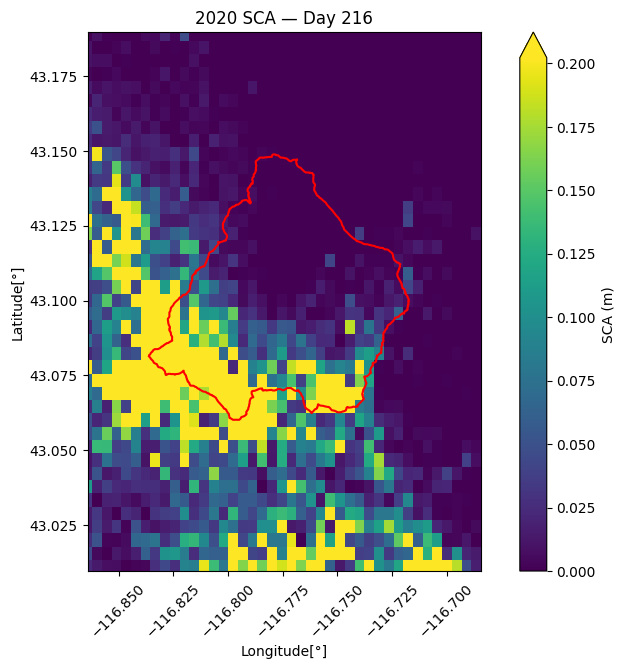

In [ ]:
## mapping one day of data
day_index = 216 # day of year that's mapped
stat_index = 0
da_day = ds["SCA_Post"].isel(Day=day_index, Stats=stat_index)

# lon/lat coordinates
da_day = da_day.assign_coords(lon=("Longitude", ds["Longitude"].values),lat=("Latitude", ds["Latitude"].values))
da_day = da_day.swap_dims({"Longitude": "lon", "Latitude": "lat"}) # swapping dimensions so lon/lat becomes dimension names
da_day = da_day.transpose("lat", "lon") # reordering lat/lon so xarray plots correctly

# computer shapefile centroid
centroid = gdf.geometry.unary_union.centroid
cx, cy = centroid.x, centroid.y

# defining zoom window
buffer_deg = 0.09 # smaller value = zoomed in, larger value = zoomed out

x_min = cx - buffer_deg
x_max = cx + buffer_deg
y_min = cy - buffer_deg
y_max = cy + buffer_deg

# plotting
fig, ax = plt.subplots(figsize=(10, 7))
mappable = da_day.plot(ax=ax, cmap="viridis", vmin=0, vmax=float(np.nanpercentile(da_day.values, 99)))
gdf.boundary.plot(ax=ax, color="red", linewidth=1.5) # adding catchment/shapefile outline

# zoom to centroid window
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.tick_params(axis="x", rotation=45)

# formatting
cbar = mappable.colorbar
cbar.set_label("SCA (m)")
ax.set_title(f"{year} SCA — Day {day_index}")
ax.set_xlabel("Longitude[\N{DEGREE SIGN}]")
ax.set_ylabel("Latitude[\N{DEGREE SIGN}]")

plt.show()

In [ ]:
## creating df of catchment mean snow cover
SCA = ds["SCA_Post"].isel(Stats=0)

#  lon/lat coordinates
SCA = SCA.assign_coords(lon=("Longitude", ds["Longitude"].values), lat=("Latitude", ds["Latitude"].values))
SCA = SCA.swap_dims({"Longitude": "lon", "Latitude": "lat"})
SCA = SCA.transpose("Day", "lat", "lon")

# build a mask of pixels inside the shapefile polygon
poly = gdf.geometry.unary_union  # merged polygon

# create 2D lon/lat grids
lon2d, lat2d = np.meshgrid(SCA.lon.values, SCA.lat.values)

# vectorized point-in-polygon test
mask = np.vectorize(lambda x, y: poly.contains(Point(x, y)))(lon2d, lat2d)
mask = mask.astype(bool) # boolean array

# compute mean SCA for each day
mean_values = []
for i in range(SCA.sizes["Day"]):
    arr = SCA.isel(Day=i).values
    mean_values.append(np.nanmean(arr[mask]))

# build table
df = pd.DataFrame({
    "Day": ds["Day"].values,
    "Mean_SCA": mean_values
})

df

/tmp/ipykernel_13567/1333781953.py:10: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  poly = gdf.geometry.unary_union  # merged polygon


,Day,Mean_SCA
0,0,0.000000e+00
1,1,0.000000e+00
2,2,0.000000e+00
3,3,0.000000e+00
4,4,0.000000e+00
...,...,...
360,360,0.000000e+00
361,361,0.000000e+00
362,362,5.022310e-02
363,363,2.424092e-02


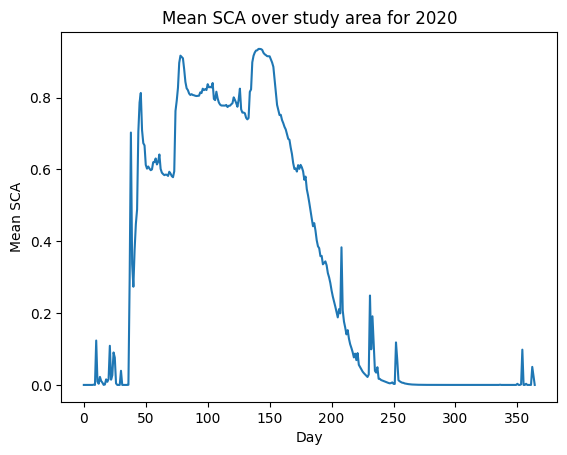

In [ ]:
## plotting and saving snow cover data
# convert df to a markdown table and save as csv
markdown_table = df.to_markdown(index=False)
#df.to_csv(f"SCA_timeseries_mean_{year}.csv", index=False) # saving df as csv
#print("\nSaved locally as SCA_timeseries_mean.csv")

# plotting
plt.plot(df['Day'], df['Mean_SCA'])
plt.xlabel('Day')
plt.ylabel('Mean SCA')
plt.title(f'Mean SCA over study area for {year}')
plt.show()